# EMQA_L2_coint_monthly

**Power, gas and hydro: the Lecture 1 regression is not spurious**

Energy Markets Quantitative Analysis (EMQA), Lecture 2 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L2/EMQA_L2_coint_monthly/EMQA_L2_coint_monthly.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# course chart style: transparent background, no grid, legend at the bottom outside the axes
plt.rcParams.update({
    "figure.facecolor": "none", "axes.facecolor": "none", "savefig.transparent": True,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#222222", "axes.labelcolor": "#222222", "xtick.color": "#222222", "ytick.color": "#222222",
    "text.color": "#222222", "font.size": 11, "axes.titlesize": 11.5, "axes.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 1.4, "font.family": "DejaVu Sans"})
PAL = {"RO": "#2a78d6", "DE_LU": "#eb6834", "HU": "#1baf7a", "BG": "#eda100",
       "c5": "#e87ba4", "c6": "#008300", "c7": "#6250d6", "c8": "#e34948"}   # fixed colour per entity


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for hh, ll in zip(*ax.get_legend_handles_labels()):
                if ll not in labels:
                    handles.append(hh)
                    labels.append(ll)
    if handles:
        fig.legend(handles, labels, loc="lower center", ncol=ncol, bbox_to_anchor=(0.5, y),
                   frameon=False, handlelength=2.0, columnspacing=1.2)

## Data and cut-off

In [3]:
TZ = "Europe/Brussels"
PD = pd.read_csv(DATA + "power_da_prices_daily_cet.csv", parse_dates=["date_cet"]).set_index("date_cet")
_hydro = pd.read_csv(DATA + "generation_ro_mw_daily_cet.csv", usecols=["date_cet", "hydro_run_of_river"],
                     parse_dates=["date_cet"]).set_index("date_cet")["hydro_run_of_river"]
# cut-off = last complete month covered by the prices and the Romanian generation data
_raw_last = min(PD["RO"].dropna().index.max(), _hydro.dropna().index.max())
END = pd.Timestamp(((_raw_last + pd.Timedelta(days=1)).to_period("M").to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp("2022-01-01")
N_TEST, N_BURN = 365, 182                                  # test year; burn-in (its forecasts only feed QRA, CP, HS)
TEST0 = END - pd.Timedelta(days=N_TEST - 1)
FC0 = TEST0 - pd.Timedelta(days=N_BURN)
FDAYS = pd.date_range(FC0, END, freq="D")                  # burn-in + test days
TDAYS = pd.date_range(TEST0, END, freq="D")                # test days
print("cut-off:", END.date(), "| test year:", TEST0.date(), "to", END.date())

cut-off: 2026-10-31 | test year: 2025-11-01 to 2026-10-31


## Monthly series: price, TTF gas and hydro (CET/CEST calendar months)

In [4]:
GH = pd.read_csv(DATA + "generation_ro_mw_hourly_utc.csv", index_col=0, usecols=["timestamp_utc", "hydro_run_of_river", "hydro_water_reservoir"])
GH.index = pd.to_datetime(GH.index, utc=True)
hyd = GH[["hydro_run_of_river", "hydro_water_reservoir"]].sum(axis=1, min_count=2)
END_UTC = (END + pd.Timedelta(days=1)).tz_localize(TZ).tz_convert("UTC")
hyd = hyd[hyd.index < END_UTC]
hyd_m = hyd.tz_convert(TZ).resample("MS").sum(min_count=600) / 1e6     # TWh per month (a month needs 600 hours)
hyd_m.index = hyd_m.index.tz_localize(None)
TTF = pd.read_csv(DATA + "ttf_monthly.csv")
TTF.index = pd.PeriodIndex(TTF["month"], freq="M").to_timestamp()
MD = pd.concat([PD["RO"].loc[:END].resample("MS").mean().rename("price"), TTF["ttf_eur_mwh"].rename("ttf"),
                hyd_m.rename("hydro")], axis=1).dropna()
MD["hydro_ds"] = MD["hydro"] - MD.groupby(MD.index.month)["hydro"].transform("mean")   # hydro minus its calendar-month mean
print(MD.index.min().strftime("%Y-%m"), "to", MD.index.max().strftime("%Y-%m"), len(MD), "months")

2015-01 to 2026-10 142 months


## Cointegration and error-correction model

In [5]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen

eg1 = coint(MD["price"], MD["ttf"], trend="c", autolag="aic")
lr_ = sm.OLS(MD["price"], sm.add_constant(MD[["ttf"]])).fit()        # long-run level from gas
u_ = lr_.resid
jo = coint_johansen(MD[["price", "ttf"]].values, det_order=0, k_ar_diff=2)
JO_RANK = (1 if jo.lr1[1] <= jo.cvt[1, 1] else 2) if jo.lr1[0] > jo.cvt[0, 1] else 0
ecm_df = pd.DataFrame({"dp": MD["price"].diff(), "u1": u_.shift(1), "dttf": MD["ttf"].diff(), "hyd": MD["hydro_ds"]}).dropna()
ecm = sm.OLS(ecm_df["dp"], sm.add_constant(ecm_df[["u1", "dttf", "hyd"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
al = ecm.params["u1"]
print(ecm.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3231      1.382      0.234      0.815      -2.386       3.032
u1            -0.4518      0.084     -5.394      0.000      -0.616      -0.288
dttf           2.1245      0.167     12.701      0.000       1.797       2.452
hyd          -12.8039      4.125     -3.104      0.002     -20.888      -4.720


## The chart

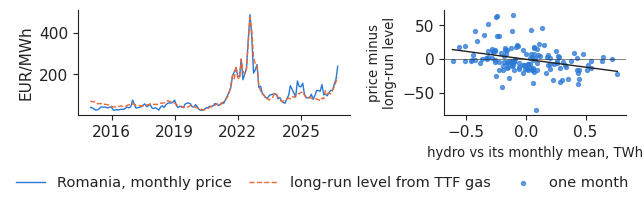

In [6]:
import matplotlib.dates as mdates
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.1), gridspec_kw={"width_ratios": [1.5, 1]})
axs[0].plot(MD.index, MD["price"], color=PAL["RO"], lw=1.0, label="Romania, monthly price")
axs[0].plot(MD.index, lr_.fittedvalues, color=PAL["DE_LU"], lw=1.0, ls="--", label="long-run level from TTF gas")
axs[0].set_ylabel("EUR/MWh")
axs[0].xaxis.set_major_locator(mdates.YearLocator(3))
axs[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axs[1].scatter(MD["hydro_ds"], u_, s=8, color=PAL["RO"], alpha=0.7, label="one month")
bb = np.polyfit(MD["hydro_ds"], u_, 1)
xx = np.linspace(MD["hydro_ds"].min(), MD["hydro_ds"].max(), 10)
axs[1].plot(xx, np.polyval(bb, xx), color="#222222", lw=1.0)
axs[1].axhline(0, color="#222222", lw=0.4)
axs[1].set_xlabel("hydro vs its monthly mean, TWh", fontsize=9.5)
axs[1].set_ylabel("price minus\nlong-run level", fontsize=9.5)
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.savefig('coint_monthly.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()

In [7]:
print("Numbers on the slide")
print(f'  first month: {MD.index.min().strftime("%Y-%m"):s}')
print(f'  last month: {MD.index.max().strftime("%Y-%m"):s}')
print(f'  Engle-Granger statistic, price on TTF: {eg1[0]:.2f}')
print(f'  Engle-Granger 5% critical value: {eg1[2][1]:.2f}')
print(f'  Johansen rank: {JO_RANK:d}')
print(f'  beta on TTF: {lr_.params["ttf"]:.3f}')
print(f'  implied gas-plant efficiency, %: {100 / lr_.params["ttf"]:.1f}')
print(f'  alpha (speed of return): {al:.3f}')
print(f'  half-life, months: {np.log(0.5) / np.log(1 + al):.1f}')
print(f'  delta, EUR/MWh per TWh of extra hydro: {ecm.params["hyd"]:.2f}')
print(f'  t-statistic of delta: {ecm.tvalues["hyd"]:.2f}')

Numbers on the slide
  first month: 2015-01
  last month: 2026-10
  Engle-Granger statistic, price on TTF: -5.64
  Engle-Granger 5% critical value: -3.38
  Johansen rank: 1
  beta on TTF: 1.947
  implied gas-plant efficiency, %: 51.4
  alpha (speed of return): -0.452
  half-life, months: 1.2
  delta, EUR/MWh per TWh of extra hydro: -12.80
  t-statistic of delta: -3.10
